## Setup

In [20]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# Thiết lập thiết bị
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")

Đang sử dụng thiết bị: cuda


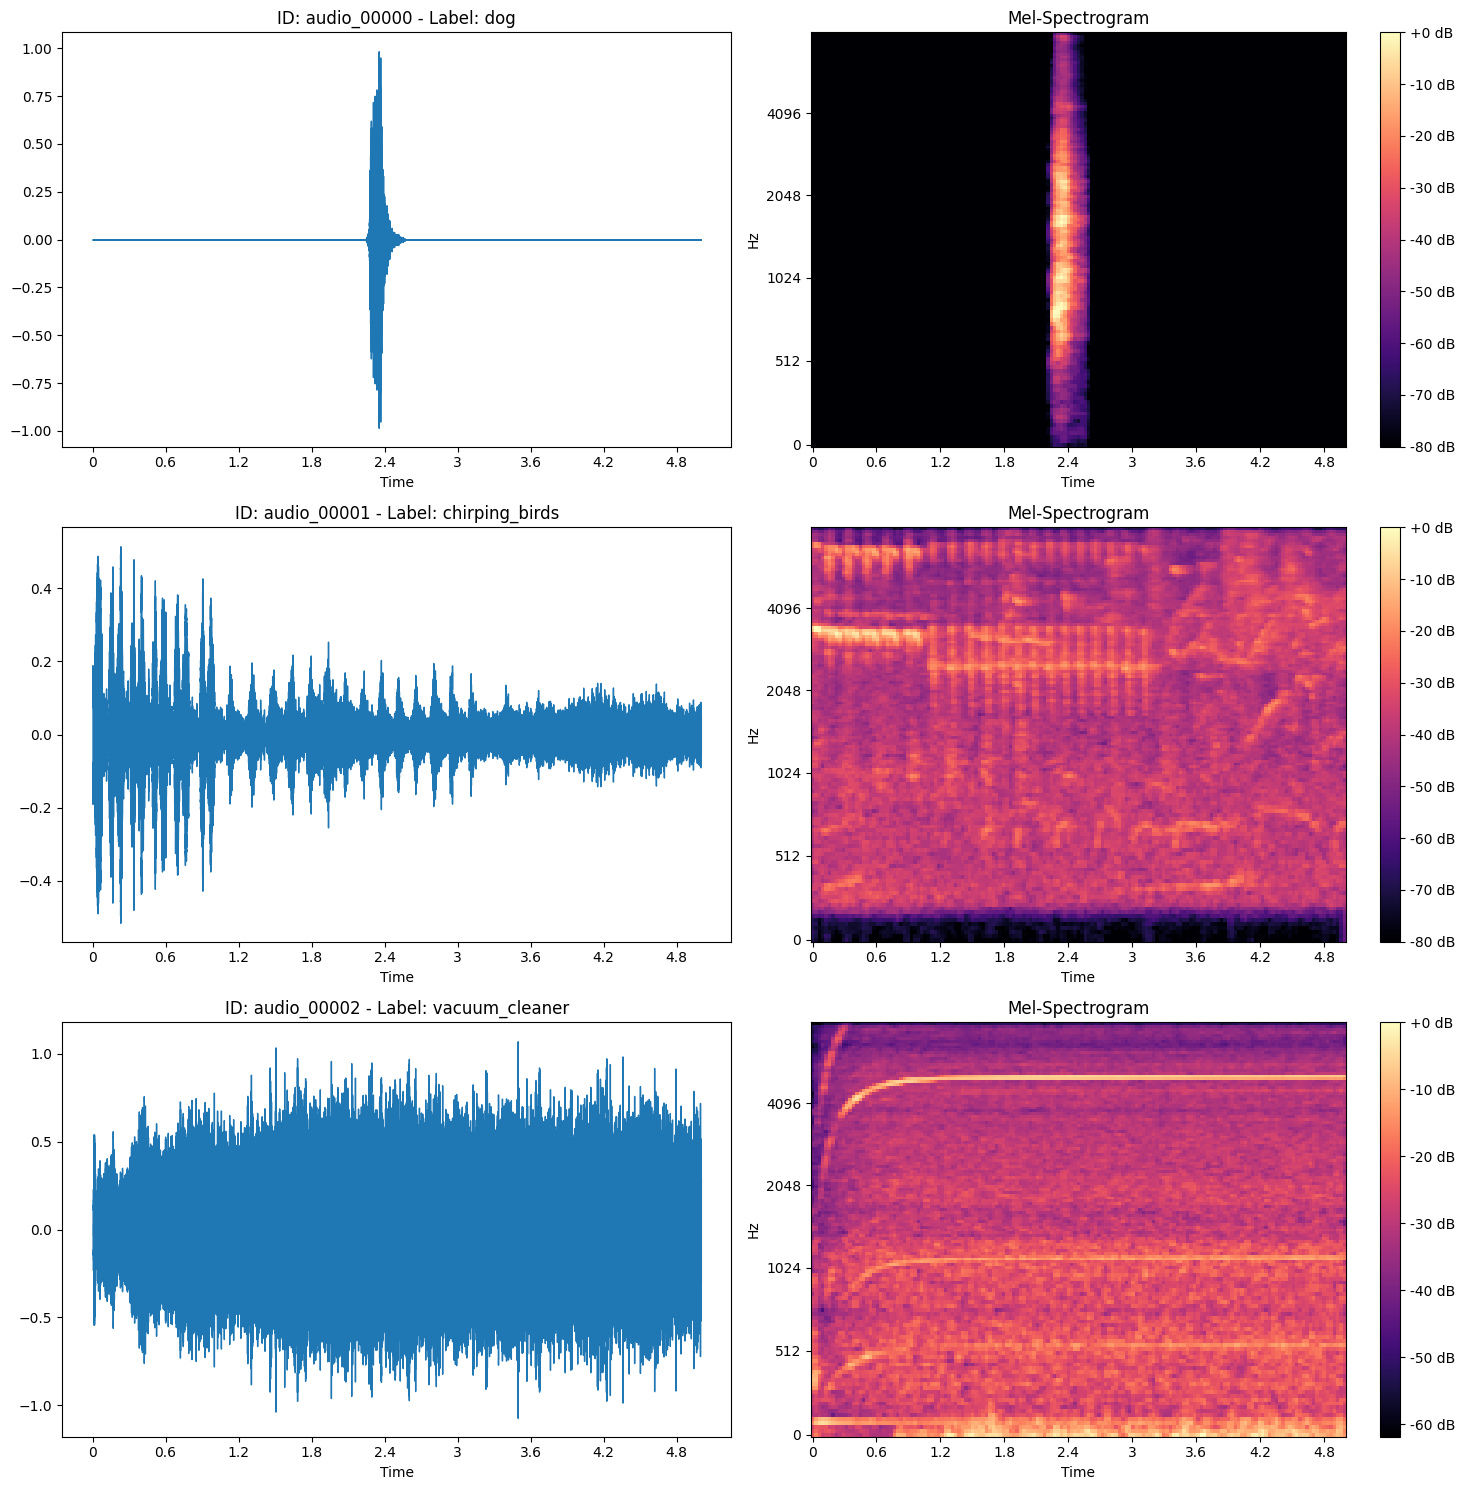

In [21]:
def plot_audio_samples(data_dir, df, num_samples=3):
    plt.figure(figsize=(15, 5 * num_samples))
    
    for i in range(num_samples):
        row = df.iloc[i]
        audio_path = os.path.join(data_dir, f"{row['id']}.wav")
        y, sr = librosa.load(audio_path, sr=16000)
        
        # Waveform
        plt.subplot(num_samples, 2, 2*i + 1)
        librosa.display.waveshow(y, sr=sr)
        plt.title(f"ID: {row['id']} - Label: {row['label']}")
        
        # Mel-Spectrogram
        plt.subplot(num_samples, 2, 2*i + 2)
        S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
        S_db = librosa.power_to_db(S, ref=np.max)
        librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel')
        plt.colorbar(format='%+2.0f dB')
        plt.title("Mel-Spectrogram")

    plt.tight_layout()
    plt.show()

# Đọc file train.csv và hiển thị
train_df = pd.read_csv('/kaggle/input/competitions/noise-classification-csp/dataset/train.csv')
plot_audio_samples('/kaggle/input/competitions/noise-classification-csp/dataset/train', train_df)

In [22]:
from transformers import AutoFeatureExtractor

class AudioDataset(Dataset):
    def __init__(self, df, data_dir, is_test=False):
        self.df = df
        self.data_dir = data_dir
        self.is_test = is_test
        self.sr = 16000
        # Feature Extractor của AST sẽ lo việc chuẩn hóa độ dài và trích xuất Mel-spectrogram
        self.feature_extractor = AutoFeatureExtractor.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        audio_id = self.df.iloc[idx]['id']
        path = os.path.join(self.data_dir, f"{audio_id}.wav")
        
        waveform, sr = torchaudio.load(path)
        if sr != self.sr:
            resampler = torchaudio.transforms.Resample(sr, self.sr)
            waveform = resampler(waveform)
        
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0)
        else:
            waveform = waveform.squeeze(0)

        # Chuyển đổi waveform thành input_values cho AST
        inputs = self.feature_extractor(
            waveform.numpy(), 
            sampling_rate=self.sr, 
            return_tensors="pt"
        )
        # inputs['input_values'] có shape [1, 1024, 128]
        input_values = inputs['input_values'].squeeze(0) 
            
        if self.is_test:
            return input_values, audio_id
        
        label = self.df.iloc[idx]['label']
        return input_values, torch.tensor(label, dtype=torch.long)

In [23]:
from transformers import AutoModelForAudioClassification

class ASTClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        model_name = "MIT/ast-finetuned-audioset-10-10-0.4593"
        print(f"--- Đang tải mô hình AST ---")
        self.ast = AutoModelForAudioClassification.from_pretrained(
            model_name, 
            num_labels=num_classes, 
            ignore_mismatched_sizes=True
        )

    def forward(self, x):
        # x bây giờ đã là Spectrogram [batch, 1024, 128]
        return self.ast(x).logits

In [24]:
from sklearn.preprocessing import LabelEncoder

# 1. Khởi tạo LabelEncoder để chuyển chữ thành số
le = LabelEncoder()
train_df['label'] = le.fit_transform(train_df['label'])

# In ra để kiểm tra các lớp đã chuyển đổi
print(f"Các lớp tìm thấy: {le.classes_}")
print(f"Ví dụ 5 dòng đầu:\n{train_df.head()}")
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.05

# Chuẩn bị DataLoaders
train_data, val_data = train_test_split(train_df, test_size=0.2, random_state=42)

train_loader = DataLoader(AudioDataset(train_data, '/kaggle/input/competitions/noise-classification-csp/dataset/train'), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(AudioDataset(val_data, '/kaggle/input/competitions/noise-classification-csp/dataset/train'), batch_size=BATCH_SIZE)

# Khởi tạo model
num_labels = train_df['label'].nunique()
model = ASTClassifier(num_labels).to(device)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()

Các lớp tìm thấy: ['airplane' 'breathing' 'brushing_teeth' 'can_opening' 'car_horn' 'cat'
 'chainsaw' 'chirping_birds' 'church_bells' 'clapping' 'clock_alarm'
 'clock_tick' 'coughing' 'cow' 'crackling_fire' 'crickets' 'crow'
 'crying_baby' 'dog' 'door_wood_creaks' 'door_wood_knock'
 'drinking_sipping' 'engine' 'fireworks' 'footsteps' 'frog'
 'glass_breaking' 'hand_saw' 'helicopter' 'hen' 'insects'
 'keyboard_typing' 'laughing' 'mouse_click' 'pig' 'pouring_water' 'rain'
 'rooster' 'sea_waves' 'sheep' 'siren' 'sneezing' 'snoring' 'thunderstorm'
 'toilet_flush' 'train' 'vacuum_cleaner' 'washing_machine' 'water_drops'
 'wind']
Ví dụ 5 dòng đầu:
            id  label
0  audio_00000     18
1  audio_00001      7
2  audio_00002     46
3  audio_00003     46
4  audio_00004     43


preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

--- Đang tải mô hình AST ---


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                        
------------------------+----------+----------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


In [25]:
for epoch in range(EPOCHS):
    model.train()
    train_loss, train_correct = 0, 0
    
    loop = tqdm(train_loader, leave=True)
    for waveforms, labels in loop:
        waveforms, labels = waveforms.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(waveforms)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        train_correct += (outputs.argmax(1) == labels).sum().item()
        
        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss=loss.item())
    
    scheduler.step()
    
    model.eval()
    val_correct = 0
    with torch.no_grad():
        for waveforms, labels in val_loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(waveforms)
            val_correct += (outputs.argmax(1) == labels).sum().item()
    
    t_acc = train_correct / len(train_data)
    v_acc = val_correct / len(val_data)
    print(f"==> Epoch {epoch+1:02d}: Train Acc: {t_acc:.4f} | Val Acc: {v_acc:.4f} | LR: {optimizer.param_groups[0]['lr']:.6f}")

  0%|          | 0/60 [00:00<?, ?it/s]

==> Epoch 01: Train Acc: 0.6885 | Val Acc: 0.8792 | LR: 0.000099


  0%|          | 0/60 [00:00<?, ?it/s]

==> Epoch 02: Train Acc: 0.9292 | Val Acc: 0.9000 | LR: 0.000096


  0%|          | 0/60 [00:00<?, ?it/s]

...

==> Epoch 13: Train Acc: 1.0000 | Val Acc: 0.9375 | LR: 0.000004


  0%|          | 0/60 [00:00<?, ?it/s]

==> Epoch 14: Train Acc: 1.0000 | Val Acc: 0.9375 | LR: 0.000001


  0%|          | 0/60 [00:00<?, ?it/s]

==> Epoch 15: Train Acc: 1.0000 | Val Acc: 0.9375 | LR: 0.000000


In [29]:
# Đường dẫn cho tập Test
BASE_DIR='/kaggle/input/competitions/noise-classification-csp/dataset'
test_csv_path = os.path.join(BASE_DIR, 'sample_submission.csv')
test_audio_dir = os.path.join(BASE_DIR, 'test')

test_df = pd.read_csv(test_csv_path)
# Khởi tạo lại Dataset cho Test
test_ds = AudioDataset(test_df, test_audio_dir, is_test=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

model.eval()
test_results = []

with torch.no_grad():
    for waveforms, ids in tqdm(test_loader, desc="Dự đoán tập Test"):
        waveforms = waveforms.to(device)
        outputs = model(waveforms)
        
        # Lấy class có xác suất cao nhất
        preds = outputs.argmax(1).cpu().numpy()
        
        # Chuyển đổi ngược từ số sang tên nhãn (nếu trước đó bạn dùng LabelEncoder)
        # Nếu cuộc thi yêu cầu nộp số thì dùng: preds_labels = preds
        preds_labels = le.inverse_transform(preds) 
        
        # FIX LỖI Ở ĐÂY: Duyệt trực tiếp qua ids (vì ids lúc này là một tuple/list các ID)
        for i, p in zip(ids, preds_labels):
            # Đảm bảo ID được giữ nguyên định dạng (str hoặc int)
            test_results.append({'id': i, 'label': p})

# Tạo DataFrame và lưu file
submission = pd.DataFrame(test_results)

# Đảm bảo thứ tự cột đúng như sample_submission
submission = submission[['id', 'label']]

submission.to_csv('submission.csv', index=False)
print("--- CHÚC MỪNG! ---")
print("Đã xuất file 'submission.csv' thành công.")

Dự đoán tập Test:   0%|          | 0/50 [00:00<?, ?it/s]

--- CHÚC MỪNG! ---
Đã xuất file 'submission.csv' thành công.
